## 01-EDA Exploratory Data Analysis for Pitt dataset

In this notebook, we are going to do EDA (Exploratory Data Analysis) on the train set, with text data

In [1]:
# import required packages
import pandas as pd
import os
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
# labels
# AD = Alzheimer's Disease (positive class)
# CN = Cognitively Normal (negative class)

In [3]:
fname = "../data/pitt/pitt_train_txt.csv"
train_df = pd.read_csv(fname)
print("Length =", len(train_df))
train_df.head()

Length = 337


,id,file,target,text,split_name
0,3,003-0.cha,AD,here's a cookie jar .\nand the lid is off the ...,train
1,5,005-0.cha,AD,the boy is slipping off the stool .\nhe's tryi...,train
2,5,005-2.cha,AD,okay ‡ he's fallin(g) off a chair .\nshe's &-...,train
3,7,007-1.cha,AD,xxx .\ncan I look at it and tell you ?\noh oka...,train
4,7,007-3.cha,AD,well the girl is telling the boy to get the co...,train


In [4]:
# build word-clouds
def make_wordcloud(text_list):
    """
    display a wordcloud based on the text list
    parameters:
        text_list: list of text (paragraphs)
    returns:
        list of frequent words        
    """
    text = "\n".join(text_list).lower()
    wordcloud = WordCloud().generate(text)

    # process text and return counts of frequent words
    result = sorted(WordCloud().process_text(text).items(), 
                    key=lambda item: item[1],
                    reverse=True
                   )
    
    
    plt.imshow(wordcloud)
    plt.axis("off")
    plt.show()

    return result

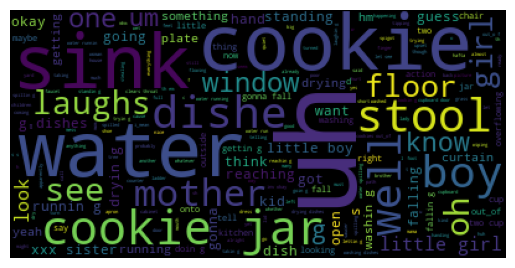

[('uh', 430), ('cookie', 177), ('water', 175), ('sink', 161), ('cookie jar', 143), ('stool', 134), ('boy', 128), ('dishe', 127), ('well', 123), ('mother', 123), ('oh', 102), ('see', 99), ('laughs', 93), ('floor', 89), ('girl', 86), ('window', 79), ('one', 76), ('know', 72), ('um', 68), ('g', 67), ('little girl', 64), ('look', 62), ('little boy', 60), ('got', 56), ('hand', 52), ('kid', 51), ('guess', 48), ('going', 48), ('xxx', 47), ('sister', 47), ('think', 46), ('dryin g', 45), ('okay', 44), ('standing', 44), ('reaching', 43), ('g dishes', 43), ('runnin g', 43), ('falling', 41), ('gonna', 41), ('open', 39), ('dish', 37), ('s', 36), ('want', 36), ('something', 35), ('getting', 35), ('running', 33), ('drying', 33), ('yeah', 33), ('washin g', 33), ('plate', 32)]


In [5]:
# see the most frequent words of AD (positive) group
ad_top_words = make_wordcloud(train_df.query("target == 'AD'")["text"].tolist())
print(ad_top_words[:50])
ad_top_words_set = set([w
                        for w, count in ad_top_words[:200]
                       ])
ad_top_words_dict = {w:count
                     for w, count in ad_top_words
                    }

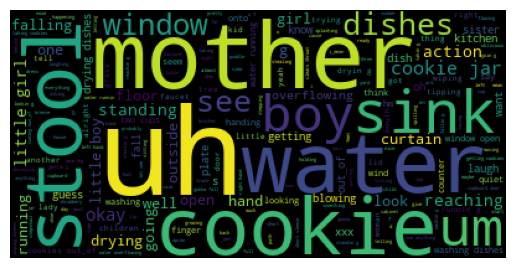

[('uh', 345), ('mother', 176), ('water', 145), ('cookie', 145), ('stool', 144), ('sink', 139), ('um', 111), ('boy', 100), ('dishes', 99), ('see', 97), ('window', 92), ('cookie jar', 86), ('okay', 80), ('action', 73), ('standing', 70), ('little girl', 69), ('reaching', 68), ('floor', 62), ('girl', 60), ('look', 59), ('g', 57), ('drying', 57), ('hand', 57), ('one', 53), ('curtain', 53), ('well', 49), ('open', 48), ('little boy', 48), ('running', 47), ('falling', 47), ('outside', 45), ('going', 44), ('overflowing', 44), ('sister', 39), ('oh', 38), ('plate', 37), ('know', 37), ('getting', 36), ('fall', 35), ('out_of', 35), ('drying dishes', 33), ('want', 32), ('blowing', 29), ('dish', 29), ('s', 27), ('guess', 27), ('kitchen', 25), ('xxx', 25), ('laugh', 25), ('washing dishes', 24)]


In [6]:
# see the most frequent words of CN (negative) group
cn_top_words = make_wordcloud(train_df.query("target == 'CN'")["text"].tolist())
print(cn_top_words[:50])
cn_top_words_set = set([w
                        for w, count in cn_top_words[:200]
                       ])
cn_top_words_dict = {w:count
                     for w, count in cn_top_words
                    }

In [7]:
# check counts of some different words
print(ad_top_words_dict["mother"])
print(cn_top_words_dict["mother"])


123
176


In [8]:
# observe the difference in 2 word set
ad_unique = ad_top_words_set - cn_top_words_set
cn_unique = cn_top_words_set - ad_top_words_set
print("AD unique words =\n", ad_unique)
print("----------------")
print("CN unique words =\n", cn_unique)


AD unique words =
 {'spilled', 'yes', 'huh', 'poor', 'laughs', 'saucer', 'turned', 'many', 'big', 'upset', 'g dishes', 'wa', 'doin g', 'out_o f', 'spigot', 'yet', 'tryin g', 'though', 'mom', 'w', 'chair', 'c', 'still', 'water run', 'coming', 'turn', 'hafta', 'inv okay', 'whatever', 'dishe', 'apparently', 'two cup', 'washed', 'u', 'already', 'th', 's s', 'mama', 'dry', 'sh', 'water spilling', 'lettin g', 'hurt', 'whether', 'th em', 'laughin g', 'spillin g', 'good', 'call', 'h', 't', 'way', 'mess'}
----------------
CN unique words =
 {'see anything', 'lip', 'obviously', 'mean', 'three', 'window open', 'putting', 'dishes', 'wearing', 'blowing', 'summer', 'shrubbery', 'o f', 'give', 'sitting', 'two cups', 'letting', 'growing', 'arm', 'side', 'tilting', 'start', 'laugh', 'view', 'asking', 'saying', 'holding', 'day', 'nose', 'water overflowing', 'short sleeve', 'laughing', 'far', 'sort', 'stepping', 'behind', 'trunk', 'moving', 'getting cookies', 'taking cookies', 'left hand', 'oblivious', '

In [9]:
ad_count = len(train_df.query("target == 'AD'"))
cn_count = len(train_df.query("target == 'CN'"))

print(f"Number of AD examples = {ad_count}, ratio = {ad_count * 100 / len(train_df) :.0f} %")
print(f"Number of CN examples = {cn_count}, ratio = {cn_count * 100 / len(train_df) :.0f} %")

Number of AD examples = 187, ratio = 55 %
Number of CN examples = 150, ratio = 45 %


We can see we have total of 337 examples, with 187 positive (AD) and 150 negative (CN). The train_set is relatively balanced (55% - 45%). 